# Edge or Cloud?
## IoT workload and network latency trace replay

**Edge led on mean delay in seven of nine scenarios at the 2× cloud CPU assumption.**
Cloud won for heavy work in the good and normal bands. Good-network light and medium work
favored edge on the mean and cloud on P95. Neither observation is a live cloud benchmark.

This notebook reads the observed network RTTs and the recorded CPU benchmark, regenerates the
results and checks them against the saved output. To execute from scratch, run the README
setup in the repository root and keep this notebook in that folder.

### 1. Inputs and coverage

Intel Berkeley Lab sensor readings form 160 windows of 64 observations. The RTT population
comes from the Stevens Network Lab release. We use only the minimum RTT field from each tier
and match by probe before discarding identifiers.

[Intel Lab source](https://db.csail.mit.edu/labdata/labdata.html) ·
[Stevens study](https://doi.org/10.1109/GLOBECOM42002.2020.9322406)

In [1]:
from pathlib import Path
import json
import subprocess
import sys
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd()
if not (root / "study.py").is_file():
    raise RuntimeError("Start Jupyter in the repository root.")
results = root / "results"
meta = json.loads((results / "run.json").read_text(encoding="utf-8"))
display(pd.DataFrame(
    {"Check": ["Raw sensor records", "Retained sensor records", "Sampled sensor readings",
               "Sampled windows", "Paired Atlas probes", "Excluded cloud-only probes"],
     "Count": [meta["sensor"][k] for k in ("raw", "clean", "sample_rows", "sample_windows")]
              + [meta["network"][k] for k in ("usable_pairs", "unmatched_cloud")]}))

,Check,Count
0,Raw sensor records,2313682
1,Retained sensor records,1794964
2,Sampled sensor readings,10240
3,Sampled windows,160
4,Paired Atlas probes,8456
5,Excluded cloud-only probes,115


### 2. Rebuild from the observed RTTs

The repository supplies the captured CPU timings so the replay is independent of the
reader's machine speed. Three kernels include JSON decoding. The cloud CPU time in the model
is the local timing divided by a speed ratio s. The baseline uses s = 2, and sensitivity
uses ratios from 1 to 8. The model starts after a window is collected and omits queueing,
protocol setup and payload transfer time.

In [2]:
def run(*parts):
    result = subprocess.run([sys.executable, *parts], cwd=root, check=True,
                            capture_output=True, text=True, encoding="utf-8")
    return result.stdout.strip()

print(run("fetch_data.py"))
bench = pd.read_csv(results / "benchmark.csv")
with TemporaryDirectory(prefix="edge-cloud-replay-") as scratch:
    print(run("study.py", "--replay-timing", "results/benchmark.csv", "--out", scratch))
    for name in ["network", "matrix", "sensitivity"]:
        pd.testing.assert_frame_equal(pd.read_csv(Path(scratch) / f"{name}.csv"),
                                      pd.read_csv(results / f"{name}.csv"),
                                      rtol=1e-12, atol=1e-12)
print(run("verify.py"))

verified intel_lab.txt.gz
verified edge.csv
verified cloud.csv


network workload  edge_mean_ms  cloud_mean_ms  delta_mean_ms  edge_win_pct mean_winner p95_winner
   Good    Light          5.41           6.10           0.69         83.08        Edge      Cloud
   Good   Medium          5.47           6.13           0.67         82.69        Edge      Cloud
   Good    Heavy         20.78          13.79          -6.99          4.29       Cloud      Cloud
 Normal    Light         10.91          15.78           4.87         88.50        Edge       Edge
 Normal   Medium         10.97          15.81           4.84         88.22        Edge       Edge
 Normal    Heavy         26.28          23.47          -2.81         37.40       Cloud      Cloud
   Poor    Light         26.07          48.82          22.75         88.01        Edge       Edge
   Poor   Medium         26.13          48.85          22.72         87.90        Edge       Edge
   Poor    Heavy         41.43          56.50          15.06         66.19        Edge       Edge


Verified 8,456 probe pairs, 9 baseline cells, and 180 sensitivity rows.


### 3. What changed when we added processing?

The bands use tertiles of nearest observed cloud RTT. The mean delta is cloud minus edge,
so positive values favor edge. Separate P95 values show the 95th-percentile modeled response
of each tier across probes, not measured per-service latency over time.

In [3]:
matrix = pd.read_csv(results / "matrix.csv")
columns = ["network", "workload", "edge_mean_ms", "cloud_mean_ms", "delta_mean_ms",
           "delta_ci_low_ms", "delta_ci_high_ms", "edge_p95_ms", "cloud_p95_ms", "p95_winner"]
display(matrix[columns].round(2))
print("Median local CPU time across 160 windows per task (ms)")
display(bench.groupby("workload")["median_ms"].median().reindex(["Light", "Medium", "Heavy"]).round(4))

,network,workload,edge_mean_ms,cloud_mean_ms,delta_mean_ms,delta_ci_low_ms,delta_ci_high_ms,edge_p95_ms,cloud_p95_ms,p95_winner
0,Good,Light,5.41,6.10,0.69,0.31,1.03,11.34,10.62,Cloud
1,Good,Medium,5.47,6.13,0.67,0.27,1.01,11.40,10.65,Cloud
2,Good,Heavy,20.78,13.79,-6.99,-7.38,-6.64,26.79,18.35,Cloud
3,Normal,Light,10.91,15.78,4.87,4.42,5.29,20.46,20.78,Edge
4,Normal,Medium,10.97,15.81,4.84,4.41,5.28,20.51,20.81,Edge
5,Normal,Heavy,26.28,23.47,-2.81,-3.28,-2.40,35.81,28.48,Cloud
6,Poor,Light,26.07,48.82,22.75,21.31,24.12,89.93,141.49,Edge
7,Poor,Medium,26.13,48.85,22.72,21.23,24.18,89.99,141.52,Edge
8,Poor,Heavy,41.43,56.50,15.06,13.59,16.51,105.53,148.98,Edge


Median local CPU time across 160 windows per task (ms)


workload
Light      0.0203
Medium     0.0814
Heavy     15.6250
Name: median_ms, dtype: float64

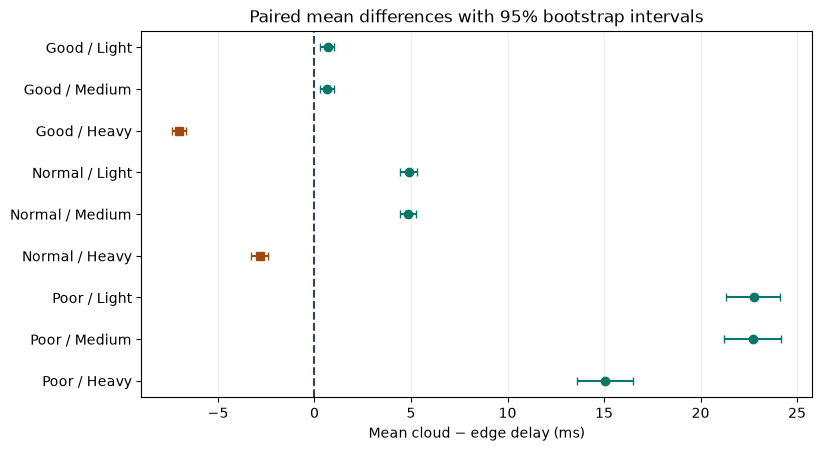

In [4]:
delta = matrix["delta_mean_ms"]
error = np.array([delta - matrix.delta_ci_low_ms, matrix.delta_ci_high_ms - delta])
fig, ax = plt.subplots(figsize=(8.1, 4.4), layout="constrained")
for index, item in matrix.iterrows():
    ax.errorbar(delta[index], index, xerr=error[:, index:index+1], capsize=3,
                marker="o" if delta[index] > 0 else "s",
                color="#087669" if delta[index] > 0 else "#9d4a15")
ax.axvline(0, linestyle="--", color="#334155")
ax.set(yticks=range(len(matrix)), yticklabels=matrix.network + " / " + matrix.workload,
       xlabel="Mean cloud − edge delay (ms)", title="Paired mean differences with 95% bootstrap intervals")
ax.invert_yaxis()
ax.grid(axis="x", alpha=.2)
plt.show()


### 4. When does the cloud catch up?

Edge wins when its network saving exceeds its extra CPU time. At mean level, the crossover
speed is mean edge CPU time divided by the difference between that time and the mean RTT
gap. There is no finite crossover when the mean gap covers all of the reference CPU time.

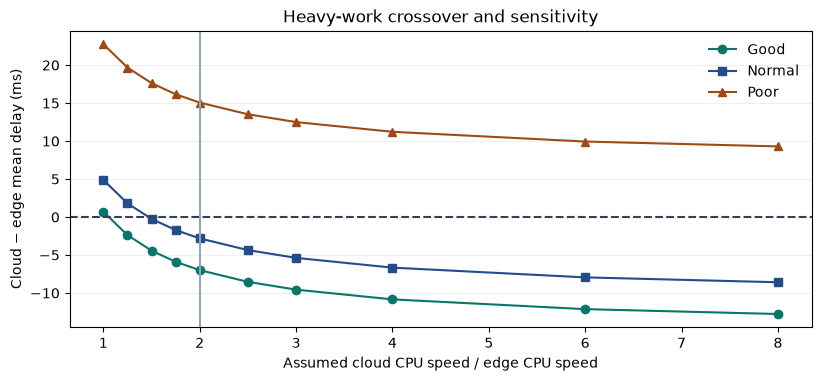

C:\Users\right click\AppData\Local\Temp\ipykernel_12832\3006188198.py:16: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  .fillna("No finite crossover"))


,network,mean_network_gap_ms,edge_cpu_mean_ms,mean_crossover_speed
2,Good,0.706,15.398,1.048
5,Normal,4.886,15.398,1.465
8,Poor,22.756,15.383,No finite crossover


In [5]:
sensitivity = pd.read_csv(results / "sensitivity.csv")
heavy = sensitivity.query('grouping == "Cloud RTT" and workload == "Heavy"')
fig, ax = plt.subplots(figsize=(8.1, 3.7), layout="constrained")
for (band, color, marker) in [("Good", "#087669", "o"), ("Normal", "#224c8a", "s"), ("Poor", "#9d4a15", "^")]:
    rows = heavy[heavy.network == band]
    ax.plot(rows.cloud_speed, rows.mean_delta_ms, marker=marker, color=color, label=band)
ax.axhline(0, linestyle="--", color="#334155")
ax.axvline(2, color="#94a3b8")
ax.set(xlabel="Assumed cloud CPU speed / edge CPU speed", ylabel="Cloud − edge mean delay (ms)",
       title="Heavy-work crossover and sensitivity")
ax.grid(axis="y", alpha=.2)
ax.legend(frameon=False)
plt.show()
display(matrix[matrix.workload == "Heavy"][
    ["network", "mean_network_gap_ms", "edge_cpu_mean_ms", "mean_crossover_speed"]].round(3)
    .fillna("No finite crossover"))


### Takeaways

- A larger RTT difference gives the edge more CPU time to spend. Poor/heavy favors edge
  on mean even when the cloud CPU cost approaches zero in the model.
- Under the fastest cloud-RTT band, lower edge mean does not guarantee lower edge P95.
- The analysis is conditional on one historical RTT release, a single CPU benchmark and
  an assumed speed factor. A deployment decision needs its own endpoint RTT, application
  service times and queueing behavior.